# 04 — Outliers contextuales y análisis multivariado: Buy to Rent en CABA

**Unidad:** publicación, no inmueble único ni transacción. **Corte:** scraping 14–17/08/2026; delitos 2023–2025.

Este notebook profundiza `03_eda_inicial.ipynb` y utiliza la salida de `02_calidad_y_limpieza.ipynb`. Es el lugar principal para clasificar outliers contextuales, medir sensibilidad y ajustar modelos que controlan simultáneamente atributos físicos, tipología, barrio y entorno. No repite el diccionario ni las distribuciones generales del EDA.

**Compromiso de conservación:** todas las filas permanecen en `df_original`; los tratamientos son por variable en una copia en memoria. No se exportan datasets, gráficos ni rankings y no se alteran fuentes. Los extremos estadísticos no se eliminan automáticamente. Los alquileres y ventas no son pares de la misma propiedad.

## 1. Reproducibilidad y trazabilidad
Ejecutar todas las celdas desde la raíz del repositorio o desde `notebooks/`. Dependencias: pandas, numpy, matplotlib, seaborn, statsmodels, IPython (y Jupyter para ejecución). La última celda registra versiones y verifica que las fuentes no cambiaron.

**Preparación del kernel (solo si faltan dependencias).** Elegir un entorno de Python con las bibliotecas anteriores. Si aparece `ModuleNotFoundError`, ejecutar en una celda temporal de Jupyter `%pip install pandas numpy matplotlib seaborn statsmodels`, reiniciar el kernel y ejecutar todo desde el inicio. `%pip` instala en el entorno del kernel seleccionado; instalar en otra terminal/Python no garantiza que ese kernel vea las dependencias. Esta indicación no ejecuta instalaciones automáticamente ni agrega archivos al repositorio.

In [1]:
from pathlib import Path
import hashlib
import sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display

sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')


def sha256(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()

# Solo se permiten dos puntos de inicio; ninguna ruta absoluta está codificada.
RAIZ = Path('.') if Path('data/processed/dataframe_limpio.csv').is_file() else Path('..')
RUTA = RAIZ / 'data/processed/dataframe_limpio.csv'
PROTEGIDOS = [RUTA, RAIZ / 'README.md', RAIZ / 'notebooks/03_eda_inicial.ipynb']
assert all(p.is_file() for p in PROTEGIDOS), 'Ejecutar desde la raíz o notebooks/.'
HASH_INICIAL = {str(p): sha256(p) for p in PROTEGIDOS}
df_original = pd.read_csv(RUTA, low_memory=False)
df = df_original.copy(deep=True)
N = len(df)
print(f'Fuente relativa: {RUTA} | Publicaciones: {N:,} | Variables: {df.shape[1]}')
print(f'Item_ID duplicados: {df.Item_ID.duplicated().sum():,}')
print('Scraping:', df.Fecha_Scraping.min()[:10], 'a', df.Fecha_Scraping.max()[:10])

Fuente relativa: data/processed/dataframe_limpio.csv | Publicaciones: 55,582 | Variables: 138
Item_ID duplicados: 0
Scraping: 2026-08-14 a 2026-08-17


La unidad observada es el aviso. La repetición de un inmueble en publicaciones distintas puede sobrerrepresentarlo; los controles de duplicación se documentan en el notebook de calidad.

## 2. Revisión y tratamiento de outliers
### 2.1 Criterios: imposibilidad, dato sospechoso y extremo plausible

- **Imposibles por dominio:** precio o superficie no positivos; cantidades negativas o fraccionarias de ambientes; distancias/conteos negativos; confort fuera de [0,1]. Se anula el valor, no la publicación.
- **Inconsistencia:** cubierta mayor que total. No se sabe cuál falló: ambas medidas se anulan para cálculos, conservando originales y bandera.
- **Centinelas o errores de escala presumidos:** superficies ≥10 millones de m², conteos ≥1 millón, expensas ≥1 millón USD/mes. Son órdenes de magnitud incompatibles con la unidad residencial del proyecto, no una demostración física. Se aparta el valor y se exige revisión de texto/origen. No se aplica un techo a precios positivos.
- **Antigüedad >150:** valor dudoso, no físicamente imposible; se sigue la política documentada de `Antiguedad_limpia` y se cuantifica su pérdida.
- **Expensas cero:** no imposible. Puede ser gasto inexistente en casa/PH o falta de información; se conserva el cero original y se usa solo gasto positivo validado para estimaciones de costos. No se imputa cero a faltantes.
- **Coordenadas marcadas:** se dejan las demás variables utilizables; los análisis geográficos/modelos no usan el entorno de esos avisos. El flag rectangular no prueba pertenencia al polígono de CABA.
- **Flags generales y de precio:** se auditan, pero no causan eliminación automática. Una venta barata o cara puede ser auténtica.

Los umbrales son decisiones reproducibles y revisables, no verdades del mercado. Los criterios del EDA se aprovechan, pero su afirmación de que todos los extremos restantes son mercado real requiere validación individual.

In [2]:
imposible = pd.DataFrame(index=df.index)
sospechoso = pd.DataFrame(index=df.index)
variables_positivas = ['Precio_USD', 'Superficie_Total_m2', 'Superficie_Cubierta_m2']
conteos = ['Ambientes', 'Dormitorios', 'Baños', 'Cocheras', 'Bauleras']
entorno = ['Distancia_Subte_m', 'Distancia_Hospital_m', 'Cantidad_Delitos_1000m',
           'Cantidad_Colectivos_500m', 'Distancia_Espacio_Verde_m',
           'Cantidad_Espacios_Verdes_1000m', 'Superficie_Verde_1000m_m2']
analizadas = variables_positivas + conteos + ['Expensas_USD', 'Antiguedad', 'Tasa_Confort_Amenities'] + entorno
for col in analizadas:
    s = pd.to_numeric(df_original[col], errors='coerce')
    df[col] = s
    imposible[col] = s.notna() & ~np.isfinite(s)
    sospechoso[col] = False
    if col in variables_positivas:
        imposible[col] |= s.le(0)
    elif col in conteos:
        imposible[col] |= s.lt(0) | (s.notna() & s.mod(1).ne(0))
        if col == 'Ambientes': imposible[col] |= s.eq(0)
        sospechoso[col] = s.ge(1_000_000)
    elif col == 'Tasa_Confort_Amenities':
        imposible[col] |= s.lt(0) | s.gt(1)
    else:
        imposible[col] |= s.lt(0)
    if col.startswith('Superficie_'): sospechoso[col] = s.ge(10_000_000)
    if col == 'Expensas_USD': sospechoso[col] = s.ge(1_000_000)
    if col == 'Antiguedad': sospechoso[col] = s.gt(150)
    df.loc[imposible[col] | sospechoso[col], col] = np.nan
inconsistencia = (df.Superficie_Cubierta_m2 > df.Superficie_Total_m2).fillna(False)
df.loc[inconsistencia, ['Superficie_Total_m2', 'Superficie_Cubierta_m2']] = np.nan
# El denominador válido determina el precio/m²; no se reutiliza sin auditar el KPI original.
df['Precio_m2_analisis'] = df.Precio_USD / df.Superficie_Total_m2
expensas_cero = df_original.Expensas_USD.eq(0)
df['Expensas_informadas_USD'] = df.Expensas_USD.where(
    df.Expensas_USD.gt(0) & df.Flag_Expensas_Anomalas.eq(0))
df['Antiguedad_analisis'] = df.Antiguedad.where(df.Antiguedad.between(0,150))
geo_valida = df.Flag_Coordenadas_Anomalas.eq(0) & df.Latitud.notna() & df.Longitud.notna()
df.loc[~geo_valida, entorno] = np.nan

auditoria = pd.DataFrame({'n_original_informado': df_original[analizadas].notna().sum(),
                         'n_imposible': imposible.sum(), 'n_sospechoso_escala': sospechoso.sum(),
                         'n_utilizable': df[analizadas].notna().sum()})
auditoria['%_utilizable_total'] = 100 * auditoria.n_utilizable / N
display(auditoria.round(2))

,n_original_informado,n_imposible,n_sospechoso_escala,n_utilizable,%_utilizable_total
Precio_USD,55582,0,0,55582,100.000
Superficie_Total_m2,55437,186,1,54977,98.910
Superficie_Cubierta_m2,54075,0,1,53801,96.800
Ambientes,55296,608,1,54687,98.390
Dormitorios,55211,0,1,55210,99.330
Baños,55295,0,1,55294,99.480
Cocheras,50378,0,1,50377,90.640
Bauleras,41877,0,1,41876,75.340
Expensas_USD,52769,0,2,52767,94.940
Antiguedad,53959,194,92,53673,96.570


Los conteos se calculan por regla y pueden superponerse. La ausencia de coordenadas válidas reduce la cobertura del entorno sin invalidar necesariamente el precio o la superficie.

In [3]:
flags = df_original.filter(regex='^Flag_').mean().mul(100).sort_values(ascending=False).to_frame('% marcado / total')
display(flags.round(2))
ceros = pd.crosstab(df_original.Tipo_Propiedad, expensas_cero).reindex(columns=[False, True], fill_value=0)
ceros.columns = ['No cero (incluye faltantes)', 'Cero original']
ceros['% cero / tipo'] = 100 * ceros['Cero original'] / ceros.sum(axis=1)
display(ceros.round(2))

,% marcado / total
Flag_Anomalia_General,61.920
Flag_Expensas_Anomalas,42.880
Flag_Balcon_Sin_Dato,38.720
Flag_Amenities_Anomalos,31.850
Flag_Expensas_Imputada,31.700
Flag_Rentabilidad_No_Calculable,23.600
Flag_Antiguedad_Cero_Sin_Estado,20.030
Flag_Aviso_Poco_Informado,20.000
Flag_Cocheras_PH_Sin_Dato,9.360
Flag_Balcon_Por_Superficie,5.780


,No cero (incluye faltantes),Cero original,% cero / tipo
Tipo_Propiedad,,,
Casa,1016,3284,76.370
Departamento,29007,16215,35.860
PH,1739,4321,71.300


La bandera general reúne problemas de gravedad distinta. En expensas, la frecuencia de ceros depende del tipo de propiedad y la tabla no distingue gastos nulos de datos sin informar.

### 2.2 Extremos contextuales: Tukey en logaritmos
Precio, superficie y precio/m² se comparan dentro de **operación × tipo de propiedad**, nunca venta contra alquiler. Se aplica 1,5×IQR a sus logaritmos; si el grupo tiene menos de 30 valores o IQR=0, no se clasifica. No usamos Tukey en cocheras/bauleras: un IQR cero confunde presencia con anomalía. Los flags nuevos indican revisión, no fraude ni error.

In [4]:
cols_out = ['Precio_USD', 'Superficie_Total_m2', 'Precio_m2_analisis']
flags_log = pd.DataFrame(False, index=df.index, columns=cols_out)
limites = []
for clave, indices in df.groupby(['Tipo_Operacion','Tipo_Propiedad']).groups.items():
    for col in cols_out:
        s = df.loc[indices, col].dropna()
        s = s[np.isfinite(s) & s.gt(0)]
        q1, q3 = np.log(s).quantile([.25,.75])
        iqr = q3-q1
        if len(s) >= 30 and iqr > 0:
            inferior, superior = np.exp(q1-1.5*iqr), np.exp(q3+1.5*iqr)
            marcado = s.lt(inferior) | s.gt(superior)
            flags_log.loc[s.index,col] = marcado
            limites.append((*clave, col, len(s), inferior, superior, marcado.sum(), 100*marcado.mean()))
limites = pd.DataFrame(limites, columns=['Operacion','Tipo','Variable','n','Limite_bajo','Limite_alto','n_extremo','%_extremo'])
display(limites.round(2))

,Operacion,Tipo,Variable,n,Limite_bajo,Limite_alto,n_extremo,%_extremo
0,Alquiler,Casa,Precio_USD,120,284.580,"19,533.130",0,0.000
1,Alquiler,Casa,Superficie_Total_m2,110,46.710,"1,553.710",2,1.820
2,Alquiler,Casa,Precio_m2_analisis,110,3.610,26.050,7,6.360
3,Alquiler,Departamento,Precio_USD,4460,138.170,"3,279.030",232,5.200
4,Alquiler,Departamento,Superficie_Total_m2,4407,14.220,182.160,183,4.150
5,Alquiler,Departamento,Precio_m2_analisis,4407,5.330,32.990,134,3.040
6,Alquiler,PH,Precio_USD,363,167.160,"3,408.470",7,1.930
7,Alquiler,PH,Superficie_Total_m2,347,14.830,420.680,4,1.150
8,Alquiler,PH,Precio_m2_analisis,347,3.610,25.430,13,3.750
9,Venta,Casa,Precio_USD,4180,"59,938.820","1,299,658.470",114,2.730


La regla de Tukey se aplica en escala logarítmica dentro de segmentos para respetar sus escalas de precio y superficie. Los casos señalados requieren contexto antes de descartar un valor.

In [5]:
revision = df_original.loc[flags_log.any(axis=1) | imposible.any(axis=1) | sospechoso.any(axis=1)].copy()
revision['Motivo_revision_TP2'] = np.select(
    [imposible.any(axis=1).loc[revision.index], sospechoso.any(axis=1).loc[revision.index]],
    ['Valor imposible en alguna variable', 'Escala sospechosa / requiere texto'], default='Extremo contextual plausible')
# Ejemplos de cada categoría, no un ranking de oportunidades; IDs permiten auditoría.
ejemplos = revision.groupby('Motivo_revision_TP2', sort=True).head(3)
display(ejemplos[['Item_ID','Tipo_Operacion','Tipo_Propiedad','Precio_USD','Superficie_Total_m2',
                  'Expensas_USD','Motivo_revision_TP2']])

,Item_ID,Tipo_Operacion,Tipo_Propiedad,Precio_USD,Superficie_Total_m2,Expensas_USD,Motivo_revision_TP2
3,MLA1945603777,Venta,Departamento,"870,000.000",241.000,841.424,Extremo contextual plausible
7,MLA1587514523,Venta,Departamento,"1,076,900.000",197.000,0.000,Extremo contextual plausible
11,MLA1663047913,Venta,Departamento,"525,000.000",82.220,511.327,Extremo contextual plausible
75,MLA1696142907,Venta,Departamento,"39,500.000",0.000,42.071,Valor imposible en alguna variable
93,MLA3763499224,Venta,Departamento,"110,000.000",48.000,71.197,Valor imposible en alguna variable
117,MLA3764209700,Venta,Departamento,"107,970.000",50.000,0.000,Valor imposible en alguna variable
127,MLA1961656335,Venta,Departamento,"298,000.000",160.000,0.000,Escala sospechosa / requiere texto
241,MLA3726717140,Venta,Departamento,"68,000.000",NaN,32.362,Escala sospechosa / requiere texto
1106,MLA3726127978,Venta,Departamento,"79,000.000",40.000,48.544,Escala sospechosa / requiere texto


Los casos de ejemplo conservan el dato publicado. Para interpretar un extremo, conviene revisar moneda, superficie y la descripción que acompañó el precio.

### 2.3 Sensibilidad, no limpieza automática
Se comparan medianas manteniendo todos los valores utilizables versus apartando, **solo como escenario**, extremos contextuales de precio/m². Los tamaños de muestra y cambios relativos permiten juzgar estabilidad sin convertir el recorte en criterio principal.

In [6]:
filas=[]
for clave, grupo in df.groupby(['Tipo_Operacion','Tipo_Propiedad']):
    s=grupo.Precio_m2_analisis.dropna()
    sin=s[~flags_log.loc[s.index,'Precio_m2_analisis']]
    filas.append((*clave,len(s),len(sin),s.median(),sin.median(),100*(sin.median()/s.median()-1)))
sensibilidad=pd.DataFrame(filas,columns=['Operacion','Tipo','n_base','n_escenario','Mediana_base','Mediana_sin_extremos','Cambio_%'])
display(sensibilidad.round(2))

,Operacion,Tipo,n_base,n_escenario,Mediana_base,Mediana_sin_extremos,Cambio_%
0,Alquiler,Casa,110,103,9.650,9.710,0.560
1,Alquiler,Departamento,4407,4273,12.760,12.630,-1.030
2,Alquiler,PH,347,334,9.960,10.000,0.430
3,Venta,Casa,4015,3937,"1,141.620","1,137.250",-0.380
4,Venta,Departamento,40473,39131,"2,351.350","2,345.990",-0.230
5,Venta,PH,5625,5549,"1,370.370","1,375.760",0.390


La comparación con y sin extremos muestra cuánto cambia la mediana de cada segmento. La mediana resume el centro de la distribución y la tabla de casos extremos permite examinar sus colas.

## 3. Resumen mínimo de variables usadas
Solo se sintetizan variables necesarias para inversión. El EDA ya desarrolla frecuencias, perfil habitacional y distribuciones extensas. Los precios de venta son capital de adquisición; los de alquiler son **mensuales**. La conversión a USD usa el dólar blue del día de scraping de cada aviso (`TC_Scraping`) y no elimina la incertidumbre cambiaria.

,Operacion,Variable,n,% sin dato utilizable,Media,Q1,Mediana,Q3
0,Alquiler,Precio_USD,4943,0.000,"1,204.450",453.070,614.890,"1,100.000"
1,Alquiler,Precio_m2_analisis,4864,1.600,17.690,10.300,12.500,16.120
2,Alquiler,Superficie_Total_m2,4864,1.600,84.290,38.000,50.000,77.000
3,Alquiler,Expensas_informadas_USD,3933,20.430,204.540,90.610,129.450,213.590
4,Alquiler,Antiguedad_analisis,4890,1.070,22.080,1.000,15.000,40.000
5,Venta,Precio_USD,50639,0.000,"221,945.830","95,000.000","146,000.000","240,000.000"
6,Venta,Precio_m2_analisis,50113,1.040,"4,228.790","1,571.430","2,156.430","2,804.000"
7,Venta,Superficie_Total_m2,50113,1.040,192.780,46.000,69.000,116.000
8,Venta,Expensas_informadas_USD,25000,50.630,168.480,71.200,110.030,182.520
9,Venta,Antiguedad_analisis,48783,3.670,23.870,0.000,13.000,46.000


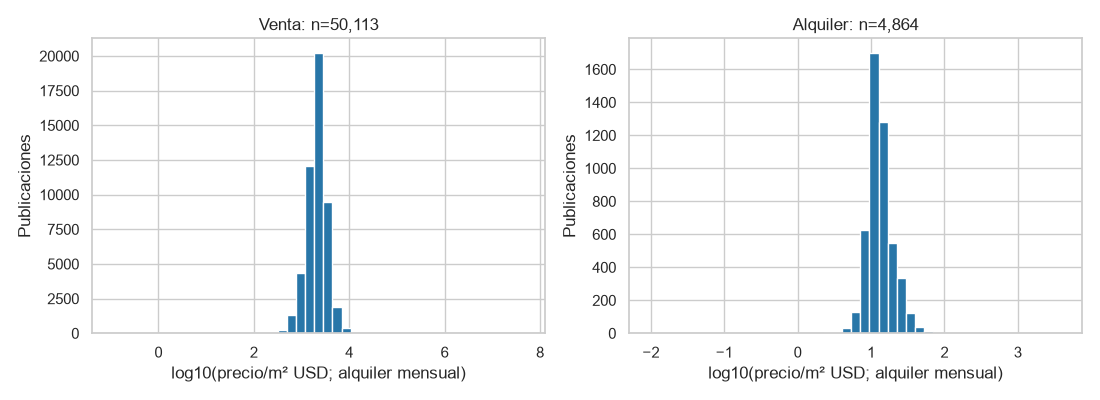

In [7]:
resumen=[]
for op, grupo in df.groupby('Tipo_Operacion'):
    for col in ['Precio_USD','Precio_m2_analisis','Superficie_Total_m2','Expensas_informadas_USD','Antiguedad_analisis']:
        s=grupo[col].dropna()
        resumen.append((op,col,len(s),100*(1-len(s)/len(grupo)),s.mean(),s.quantile(.25),s.median(),s.quantile(.75)))
resumen=pd.DataFrame(resumen,columns=['Operacion','Variable','n','% sin dato utilizable','Media','Q1','Mediana','Q3'])
display(resumen.round(2))
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,op in zip(axs,['Venta','Alquiler']):
    s=df.loc[df.Tipo_Operacion.eq(op),'Precio_m2_analisis'].dropna()
    ax.hist(np.log10(s),bins=45,color='#2876a8')
    ax.set(title=f'{op}: n={len(s):,}',xlabel='log10(precio/m² USD; alquiler mensual)',ylabel='Publicaciones')
plt.tight_layout(); plt.show()

Cada variable usa su propia cobertura. La renta mensual por m² y el precio de venta por m² tienen unidades de tiempo diferentes.

**Lectura del resultado ejecutado.** La mediana de venta es USD 146.000, con 69 m² de superficie; la renta publicada mediana es USD 624,18 mensuales, con 50 m². Son universos distintos: dividir estas dos medianas globales produciría una comparación de composición, no el retorno de una propiedad. Solo 25.000 de 50.639 ventas (49,37%) tienen expensas positivas validadas; los costos no se conocen para la otra mitad. Las medias de precio/m² y superficie siguen siendo sensibles a valores positivos sospechosos: se priorizan medianas y auditoría de las colas.

## 4. Validaciones bivariadas previas al modelo
### 4.1 Precio y superficie; composición de oferta
Las relaciones se separan por operación. Spearman mide asociación monótona, no causalidad. El precio/m² tiene superficie en su denominador: una relación con tamaño puede ser parcialmente algebraica.

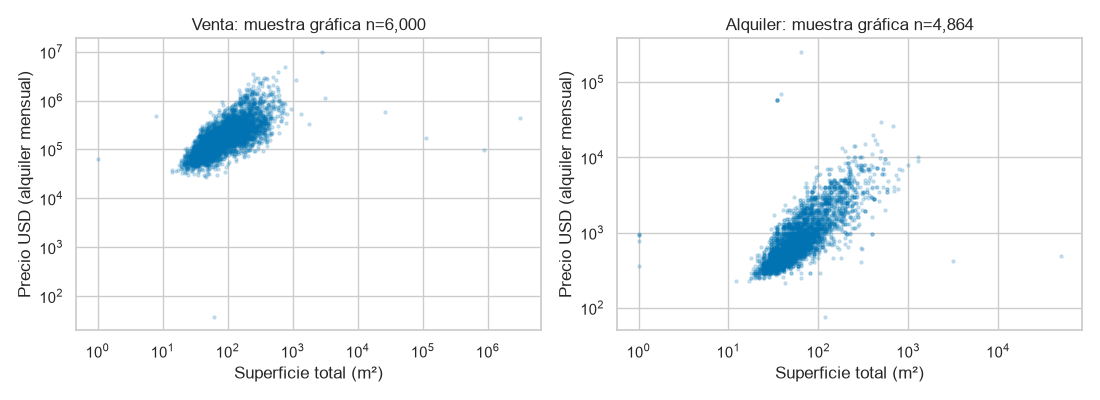

,Operacion,n_pares,rho_precio_superficie,rho_m2_superficie
0,Venta,50113,0.771,-0.255
1,Alquiler,4864,0.799,-0.056


In [8]:
bivariadas=[]
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,op in zip(axs,['Venta','Alquiler']):
    g=df.loc[df.Tipo_Operacion.eq(op),['Precio_USD','Superficie_Total_m2','Precio_m2_analisis']].dropna()
    bivariadas.append((op,len(g),g.Precio_USD.corr(g.Superficie_Total_m2,method='spearman'),
                       g.Precio_m2_analisis.corr(g.Superficie_Total_m2,method='spearman')))
    muestra=g.sample(n=min(6000,len(g)),random_state=42)
    ax.scatter(muestra.Superficie_Total_m2,muestra.Precio_USD,s=5,alpha=.18)
    ax.set(xscale='log',yscale='log',xlabel='Superficie total (m²)',ylabel='Precio USD (alquiler mensual)',title=f'{op}: muestra gráfica n={len(muestra):,}')
plt.tight_layout(); plt.show()
bivariadas=pd.DataFrame(bivariadas,columns=['Operacion','n_pares','rho_precio_superficie','rho_m2_superficie'])
display(bivariadas.round(3))

Los gráficos muestran una muestra para facilitar la lectura. La correlación usa todos los pares válidos y puede reflejar diferencias de barrio, tipología y calidad.

**Lectura del resultado ejecutado.** Precio y superficie tienen asociación monótona fuerte: rho=0,771 en venta y 0,800 en alquiler. Precio/m² y tamaño se relacionan negativamente en venta (−0,255), pero muy débilmente en alquiler (−0,061). Esto sugiere que el capital de adquisición no escala de forma estrictamente proporcional al área; no demuestra descuento causal por tamaño y exige controlar barrio/tipo.

n   n_m2  mediana_m2  mediana_superficie
Tipo_Operacion Tipo_Propiedad                                              
Alquiler       Casa              120    110       9.650             255.500
               Departamento     4460   4407      12.760              48.000
               PH                363    347       9.960              80.000
Venta          Casa             4180   4015   1,141.620             253.000
               Departamento    40762  40473   2,351.350              60.000
               PH               5697   5625   1,370.370             117.000

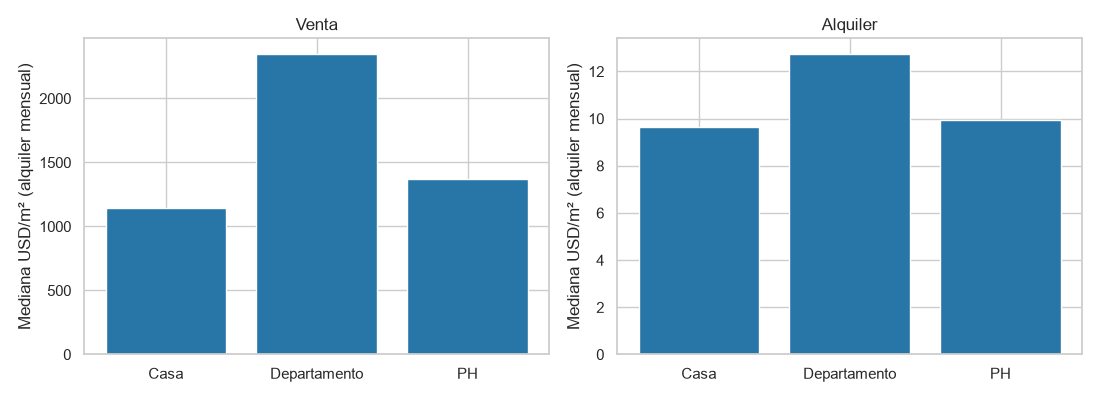

In [9]:
tipos=df.groupby(['Tipo_Operacion','Tipo_Propiedad']).agg(n=('Item_ID','size'),n_m2=('Precio_m2_analisis','count'),
    mediana_m2=('Precio_m2_analisis','median'),mediana_superficie=('Superficie_Total_m2','median'))
display(tipos.round(2))
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,op in zip(axs,['Venta','Alquiler']):
    tab=tipos.loc[op]
    ax.bar(tab.index,tab.mediana_m2,color='#2876a8')
    ax.set(title=op,ylabel='Mediana USD/m² (alquiler mensual)')
plt.tight_layout(); plt.show()

Las medianas por tipo reflejan composiciones diferentes. La comparación de compra y alquiler en los segmentos de la sección 6 es más informativa para Buy to Rent.

### 4.2 Entorno urbano: H4, H5 y H7
El EDA identifica **H4: transporte**, **H5: delitos** y **H7: espacios verdes/unidades familiares**. Los archivos revisados no contienen su formulación formal completa ni H1–H3/H6: se analiza la dirección de asociación pertinente, sin inventar hipótesis o dar por verificada una redacción ausente. Delitos es conteo 2023–2025, no tasa de riesgo personal. La superficie verde disponible es preferible aquí a una distancia casi saturada según el EDA.

In [10]:
entorno_corr=[]
for op,g in df.groupby('Tipo_Operacion'):
    for col in ['Distancia_Subte_m','Cantidad_Delitos_1000m','Superficie_Verde_1000m_m2','Tasa_Confort_Amenities']:
        par=g[['Precio_m2_analisis',col]].dropna()
        entorno_corr.append((op,col,len(par),par.iloc[:,0].corr(par.iloc[:,1],method='spearman')))
entorno_corr=pd.DataFrame(entorno_corr,columns=['Operacion','Predictor','n_pares','Spearman'])
display(entorno_corr.round(3))

,Operacion,Predictor,n_pares,Spearman
0,Alquiler,Distancia_Subte_m,4848,0.045
1,Alquiler,Cantidad_Delitos_1000m,4848,-0.073
2,Alquiler,Superficie_Verde_1000m_m2,4848,0.338
3,Alquiler,Tasa_Confort_Amenities,4864,0.475
4,Venta,Distancia_Subte_m,50028,-0.096
5,Venta,Cantidad_Delitos_1000m,50028,-0.007
6,Venta,Superficie_Verde_1000m_m2,50028,0.149
7,Venta,Tasa_Confort_Amenities,50113,0.481


La centralidad y la circulación pueden afectar simultáneamente registros de delitos y precios. Estas correlaciones descriptivas ayudan a decidir qué variables considerar en el ajuste siguiente.

n       P25  mediana_m2       P75
Tipo_Operacion Familiar Verde_cuartil                                      
Alquiler       False    Q1 menor        683    10.280      11.900    13.710
                        Q2              682    10.360      11.870    14.560
                        Q3              777    10.520      12.370    14.510
                        Q4 mayor        970    11.930      14.940    22.860
               True     Q1 menor        285     8.630      10.340    12.820
                        Q2              306     9.250      11.330    14.590
                        Q3              415     9.070      11.410    15.590
                        Q4 mayor        645    10.600      14.940    21.480
Venta          False    Q1 menor       5560 1,886.600   2,298.010 2,782.790
                        Q2             5407 1,865.160   2,342.110 2,858.540
                        Q3             5707 1,933.330   2,363.640 2,842.620
                        Q4 mayor       4939 2,062.670   2,666.670 3,519.770
               True     Q1 menor       7013 1,275.380   1,750.000 2,368.420
                        Q2             7097 1,348.310   1,850.000 2,566.370
                        Q3             6605 1,343.750   1,894.740 2,566.670
                        Q4 mayor       6932 1,338.510   2,195.090 3,333.330

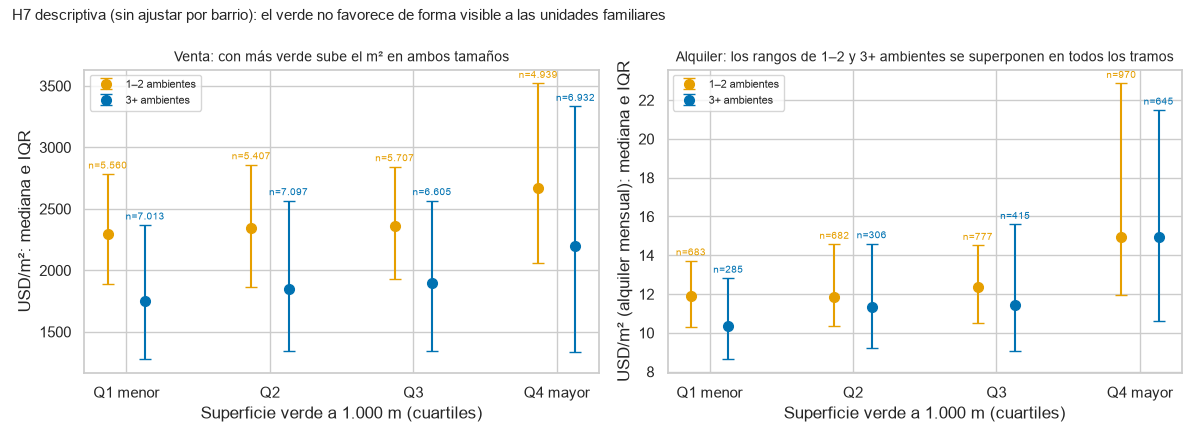

In [11]:
df['Familiar']=df.Ambientes.ge(3).where(df.Ambientes.notna()).astype('boolean')
# Cuartiles globales del entorno válido, aplicados igual a familiares/no familiares.
df['Verde_cuartil']=pd.qcut(df.Superficie_Verde_1000m_m2,4,labels=['Q1 menor','Q2','Q3','Q4 mayor'],duplicates='raise')
verde=df.groupby(['Tipo_Operacion','Familiar','Verde_cuartil'],observed=True).Precio_m2_analisis.agg(
    n='count',P25=lambda s:s.quantile(.25),mediana_m2='median',P75=lambda s:s.quantile(.75))
display(verde.round(2))
# Puntos con mediana, rango intercuartil y n por tramo. No se unen con líneas: los cuartiles mezclan barrios y tipos,
# y una línea sugeriría una tendencia más firme que la evidencia.
fig,axs=plt.subplots(1,2,figsize=(12,4.4))
colores_h7={False:'#E69F00',True:'#0072B2'}
for ax,op in zip(axs,['Venta','Alquiler']):
    tab=verde.loc[op].reset_index()
    for k,(familiar,g) in enumerate(tab.groupby('Familiar')):
        xs=g.Verde_cuartil.cat.codes.to_numpy()+(k-.5)*.26
        ax.errorbar(xs,g.mediana_m2,yerr=[g.mediana_m2-g.P25,g.P75-g.mediana_m2],fmt='o',color=colores_h7[familiar],
                    capsize=4,markersize=7,label='3+ ambientes' if familiar else '1–2 ambientes')
        for xi,(_,r) in zip(xs,g.iterrows()):
            ax.annotate(f'n={int(r.n):,}'.replace(',','.'),(xi,r.P75),xytext=(0,4),textcoords='offset points',ha='center',fontsize=7,color=colores_h7[familiar])
    ax.set_xticks(range(4),df.Verde_cuartil.cat.categories)
    unidad='USD/m² (alquiler mensual)' if op=='Alquiler' else 'USD/m²'
    ax.set(ylabel=f'{unidad}: mediana e IQR',xlabel='Superficie verde a 1.000 m (cuartiles)')
    ax.legend(fontsize=8,loc='upper left')
axs[0].set_title('Venta: con más verde sube el m² en ambos tamaños',fontsize=10)
axs[1].set_title('Alquiler: los rangos de 1–2 y 3+ ambientes se superponen en todos los tramos',fontsize=10)
fig.suptitle('H7 descriptiva (sin ajustar por barrio): el verde no favorece de forma visible a las unidades familiares',x=.01,ha='left',fontsize=11)
plt.tight_layout(); plt.show()

Las barras representan el intervalo intercuartílico. Los cuartiles de verde mezclan barrios y tipos, y tres ambientes o más se usa como indicador del tamaño de la vivienda.

**Lectura del resultado ejecutado.** En alquiler, el precio/m² mediano de 3+ ambientes pasa de USD 10,40/mes en el cuartil de menor superficie verde a USD 15,15 en el mayor; las unidades de 1–2 ambientes pasan de 12,05 a 15,09. En venta ambas categorías también aumentan hacia Q4, aunque los niveles son diferentes. La comparación visual es compatible con asociación verde-precio, pero no aísla el componente familiar: mezcla zonas y tipos. La interpretación de H7 depende del ajuste y de su sensibilidad, no de estas líneas solas.

## 5. Análisis multivariado orientado a Buy to Rent
### 5.1 Dos modelos hedónicos descriptivos
Se modela **log(precio USD)** por separado para venta y alquiler no declarado temporario. Covariables: log(superficie), ambientes, antigüedad, confort informado, log(1+distancia al subte), log(1+delitos), log(1+superficie verde), interacción verde × 3+ ambientes y efectos de barrio y tipo. Los efectos de barrio comparan dentro de barrio; no resuelven ubicación microespacial ni selección.

**No se predice rentabilidad con sus componentes**, ni se incluyen `Indice_Subvaluacion`, `Precio_Predicho_USD` o `Rentabilidad_Neta_Zona`: son KPIs construidos y generarían circularidad/fuga. El target es precio publicado, no precio de cierre ni renta efectivamente percibida. Casos completos, sin imputación automática; el sesgo de selección se cuantifica. Se retienen extremos contextuales en el modelo base; HC3 trata heterocedasticidad, no dependencia espacial.

In [12]:
df['log_precio']=np.log(df.Precio_USD)
df['log_superficie']=np.log(df.Superficie_Total_m2)
df['log_subte']=np.log1p(df.Distancia_Subte_m)
df['log_delitos']=np.log1p(df.Cantidad_Delitos_1000m)
df['log_verde']=np.log1p(df.Superficie_Verde_1000m_m2)
df['familiar_num']=df.Familiar.astype('Float64').astype(float)
variables_modelo=['log_precio','log_superficie','Ambientes','Antiguedad_analisis','Tasa_Confort_Amenities',
                  'log_subte','log_delitos','log_verde','familiar_num','Barrio_Normalizado','Tipo_Propiedad']
formula=('log_precio ~ log_superficie + Ambientes + Antiguedad_analisis + Tasa_Confort_Amenities '
         '+ log_subte + log_delitos + log_verde * familiar_num + C(Barrio_Normalizado) + C(Tipo_Propiedad)')
modelos={}; bases={}; cobertura=[]
for op in ['Venta','Alquiler']:
    elegible=df.Tipo_Operacion.eq(op) & df.Flag_Operacion_Anomala.eq(0)
    if op=='Alquiler': elegible &= ~df.Tipo_Alquiler.eq('Temporario')
    base=df.loc[elegible].dropna(subset=variables_modelo).copy()
    bases[op]=base
    modelos[op]=smf.ols(formula,data=base).fit(cov_type='HC3')
    cobertura.append((op,int(elegible.sum()),len(base),100*len(base)/elegible.sum(),
                      df.loc[elegible,'Precio_USD'].median(),base.Precio_USD.median(),modelos[op].rsquared))
cobertura=pd.DataFrame(cobertura,columns=['Operacion','n_elegible','n_completo','Cobertura_%','Mediana_elegible','Mediana_modelo','R2_in_sample'])
display(cobertura.round(3))

,Operacion,n_elegible,n_completo,Cobertura_%,Mediana_elegible,Mediana_modelo,R2_in_sample
0,Venta,50555,47302,93.565,"146,000.000","148,000.000",0.840
1,Alquiler,4619,4387,94.977,600.000,601.942,0.789


Las medianas de casos elegibles y completos permiten detectar qué parte de la base usa el modelo. El ajuste dentro de muestra caracteriza esa población.

,Operacion,Termino,beta,IC95_inf_HC3,IC95_sup_HC3
0,Venta,log_superficie,0.695,0.648,0.742
1,Venta,Ambientes,0.038,0.025,0.050
2,Venta,Antiguedad_analisis,-0.005,-0.005,-0.005
3,Venta,Tasa_Confort_Amenities,0.524,0.498,0.551
4,Venta,log_subte,0.002,-0.002,0.007
5,Venta,log_delitos,-0.037,-0.047,-0.027
6,Venta,log_verde,0.009,0.006,0.011
7,Venta,familiar_num,0.048,0.007,0.088
8,Venta,log_verde:familiar_num,0.008,0.004,0.012
9,Alquiler,log_superficie,0.512,0.359,0.665


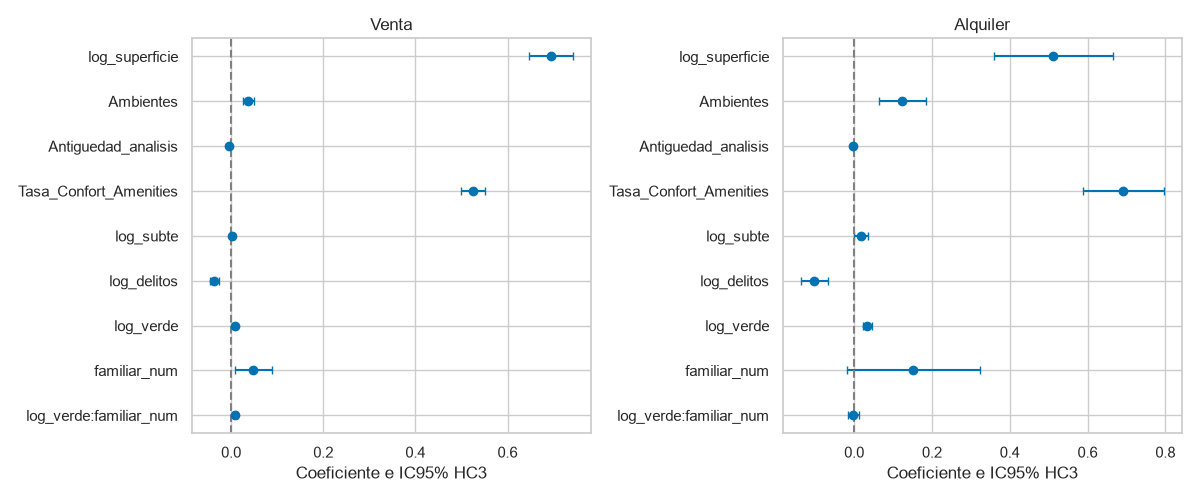

In [13]:
terminos=['log_superficie','Ambientes','Antiguedad_analisis','Tasa_Confort_Amenities',
          'log_subte','log_delitos','log_verde','familiar_num','log_verde:familiar_num']
coef=[]
for op,m in modelos.items():
    ci=m.conf_int()
    for t in terminos:
        coef.append((op,t,m.params[t],ci.loc[t,0],ci.loc[t,1]))
coef=pd.DataFrame(coef,columns=['Operacion','Termino','beta','IC95_inf_HC3','IC95_sup_HC3'])
display(coef.round(4))
fig,axs=plt.subplots(1,2,figsize=(12,5))
for ax,op in zip(axs,['Venta','Alquiler']):
    t=coef.loc[coef.Operacion.eq(op)].set_index('Termino').iloc[::-1]
    ax.errorbar(t.beta,t.index,xerr=[t.beta-t.IC95_inf_HC3,t.IC95_sup_HC3-t.beta],fmt='o',capsize=3)
    ax.axvline(0,color='gray',linestyle='--'); ax.set(title=op,xlabel='Coeficiente e IC95% HC3')
plt.tight_layout(); plt.show()

La interacción con verde compara la pendiente entre tamaños de vivienda. La pendiente total para unidades grandes suma la pendiente de base y la interacción. Los intervalos de esta exploración se complementan con los contrastes agrupados por barrio.

### 5.2 Diagnóstico y sensibilidad multivariada
No basta un R²: se revisan residuos y se compara el ajuste base con un escenario sin flags contextuales. El modelo trabaja en log-precio y no debe extrapolarse a ofertas sin cobertura o propiedades fuera del universo. No se elige el escenario por su mejor significancia.

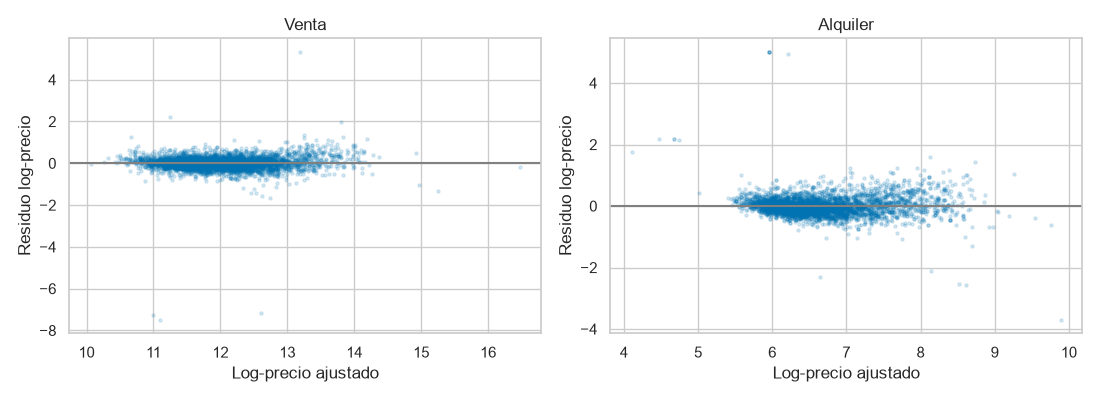

,Operacion,n,RMSE_log_in_sample,Mediana_abs_residuo,Condicion_matriz
0,Venta,47302,0.284,0.151,"4,959.708"
1,Alquiler,4387,0.336,0.154,"6,343.229"


,Operacion,Termino,n_base,n_sensibilidad,beta_base,beta_sensibilidad,Delta_beta
0,Venta,log_superficie,47302,45047,0.695,0.757,0.062
1,Venta,log_subte,47302,45047,0.002,0.002,0.000
2,Venta,log_delitos,47302,45047,-0.037,-0.007,0.030
3,Venta,log_verde:familiar_num,47302,45047,0.008,-0.007,-0.015
4,Alquiler,log_superficie,4387,4057,0.512,0.649,0.137
5,Alquiler,log_subte,4387,4057,0.017,0.009,-0.007
6,Alquiler,log_delitos,4387,4057,-0.102,-0.071,0.031
7,Alquiler,log_verde:familiar_num,4387,4057,-0.002,-0.012,-0.010


In [14]:
diagnosticos=[]; comparacion=[]
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,op in zip(axs,['Venta','Alquiler']):
    m=modelos[op]; b=bases[op]
    idx=np.random.default_rng(42).choice(len(b),min(5000,len(b)),replace=False)
    ax.scatter(np.asarray(m.fittedvalues)[idx],np.asarray(m.resid)[idx],s=5,alpha=.15)
    ax.axhline(0,color='gray'); ax.set(title=op,xlabel='Log-precio ajustado',ylabel='Residuo log-precio')
    condicion=np.linalg.cond(m.model.exog)
    diagnosticos.append((op,len(b),np.sqrt(np.mean(m.resid**2)),np.median(np.abs(m.resid)),condicion))
    limpio=b.loc[~flags_log.loc[b.index].any(axis=1)]
    ms=smf.ols(formula,data=limpio).fit(cov_type='HC3')
    for t in ['log_superficie','log_subte','log_delitos','log_verde:familiar_num']:
        comparacion.append((op,t,len(b),len(limpio),m.params[t],ms.params[t],ms.params[t]-m.params[t]))
plt.tight_layout(); plt.show()
display(pd.DataFrame(diagnosticos,columns=['Operacion','n','RMSE_log_in_sample','Mediana_abs_residuo','Condicion_matriz']).round(3))
display(pd.DataFrame(comparacion,columns=['Operacion','Termino','n_base','n_sensibilidad','beta_base','beta_sensibilidad','Delta_beta']).round(4))

Los diagnósticos muestran dispersión residual y sensibilidad a extremos. La condición de la matriz advierte que superficie, ambientes y el indicador familiar pueden compartir información.

**Resultado clave de la sensibilidad.** En venta, la interacción verde × 3+ ambientes cambia de **+0,008** en la base a **−0,007** al apartar extremos contextuales. Por eso el aparente apoyo ajustado a H7 **no es robusto** a este escenario; no se concluye un premio familiar diferencial estable. El efecto delitos permanece negativo, pero pasa de −0,037 a −0,007 en venta y de −0,101 a −0,066 en alquiler: su magnitud es sensible. La pendiente de superficie cambia de 0,695 a 0,757 en venta y de 0,510 a 0,647 en alquiler. Los residuos muestran valores muy alejados de cero y mayor dispersión en ciertas zonas del ajuste; conviene auditar publicaciones y especificación antes de usar predicciones.

## 6. Comparables y escenarios Buy to Rent
### 6.1 Rendimiento de segmentos, no de una unidad observada
Se recalculan comparables de **barrio × tipo × ambientes (1/2/3/4+)** con ≥5 ventas y ≥5 alquileres por grupo. Se requieren precio/superficie utilizables y flags de operación y tipo sin conflicto. No se impone el recorte p1–p99 del KPI original: se conserva la cola plausible. El escenario amplio excluye temporarios explícitos pero contiene alquileres desconocidos; el estricto usa solo tradicionales confirmados. Ambos se muestran.

`Renta_bruta = 12 × mediana(alquiler mensual USD) / mediana(precio venta USD)`.
Es una razón de medianas de publicaciones distintas; no tasa de retorno realizada. Las medianas pueden combinar tamaños diferentes incluso dentro del mismo número de ambientes: se informa su diferencia. `Rentabilidad_Neta_Zona` se compara solo como KPI previo, no evidencia independiente.

In [15]:
df['Ambientes_TP2']=pd.cut(df.Ambientes,[.5,1.5,2.5,3.5,np.inf],labels=['1','2','3','4+'])
claves=['Barrio_Normalizado','Tipo_Propiedad','Ambientes_TP2']
valido=(df.Precio_USD.gt(0) & df.Superficie_Total_m2.gt(0) & df.Flag_Operacion_Anomala.eq(0)
        & df.Flag_Tipo_Propiedad_Anomalo.eq(0) & df[claves].notna().all(axis=1))
ventas=df.loc[valido & df.Tipo_Operacion.eq('Venta')]
alquiler_amplio=df.loc[valido & df.Tipo_Operacion.eq('Alquiler') & ~df.Tipo_Alquiler.eq('Temporario')]
alquiler_estricto=alquiler_amplio.loc[alquiler_amplio.Tipo_Alquiler.eq('Tradicional')]

def agregar_grupos(datos):
    return datos.groupby(claves,observed=True).agg(n=('Item_ID','size'),precio=('Precio_USD','median'),
        superficie=('Superficie_Total_m2','median'),expensas=('Expensas_informadas_USD','median'),
        n_expensas=('Expensas_informadas_USD','count'))

def comparables(alquileres,minimo=5):
    v=agregar_grupos(ventas); a=agregar_grupos(alquileres)
    c=v.add_suffix('_venta').join(a.add_suffix('_alquiler'),how='inner')
    c=c.loc[c.n_venta.ge(minimo) & c.n_alquiler.ge(minimo)].copy()
    c['Bruta_%']=1200*c.precio_alquiler/c.precio_venta
    c['Diferencia_superficie_%']=100*(c.superficie_alquiler/c.superficie_venta-1)
    return c

comparables_amplios=comparables(alquiler_amplio)
comparables_estrictos=comparables(alquiler_estricto)
cover=[]
for nombre,a,c in [('Amplio no temporario explícito',alquiler_amplio,comparables_amplios),
                   ('Tradicional confirmado',alquiler_estricto,comparables_estrictos)]:
    cover.append((nombre,len(a),len(c),int(c.n_venta.sum()),int(c.n_alquiler.sum()),c['Bruta_%'].median()))
cobertura_renta=pd.DataFrame(cover,columns=['Escenario','n_alquiler_elegible','n_grupos','n_ventas_en_grupos','n_alquiler_en_grupos','Mediana_bruta_%_por_grupo'])
display(cobertura_renta.round(2))
display(comparables_amplios[['n_venta','n_alquiler','superficie_venta','superficie_alquiler','Diferencia_superficie_%','Bruta_%']].sort_values('n_alquiler',ascending=False).head(12).round(2))

,Escenario,n_alquiler_elegible,n_grupos,n_ventas_en_grupos,n_alquiler_en_grupos,Mediana_bruta_%_por_grupo
0,Amplio no temporario explícito,4351,133,36391,4012,5.830
1,Tradicional confirmado,221,12,5342,88,4.450


n_venta  n_alquiler  \
Barrio_Normalizado Tipo_Propiedad Ambientes_TP2                        
Puerto Madero      Departamento   2                  396         172   
Palermo            Departamento   2                  575         172   
Belgrano           Departamento   2                  570         149   
Palermo            Departamento   1                  469         147   
Caballito          Departamento   2                  544         139   
Recoleta           Departamento   2                  401         124   
                                  1                  387         114   
                                  3                  391         103   
Puerto Madero      Departamento   3                  457          98   
Recoleta           Departamento   4+                 783          97   
Belgrano           Departamento   1                  356          93   
Palermo            Departamento   3                  442          89   

                                                 superficie_venta  \
Barrio_Normalizado Tipo_Propiedad Ambientes_TP2                     
Puerto Madero      Departamento   2                        70.000   
Palermo            Departamento   2                        52.000   
Belgrano           Departamento   2                        53.050   
Palermo            Departamento   1                        37.000   
Caballito          Departamento   2                        51.550   
Recoleta           Departamento   2                        50.000   
                                  1                        35.000   
                                  3                        86.000   
Puerto Madero      Departamento   3                       127.000   
Recoleta           Departamento   4+                      167.000   
Belgrano           Departamento   1                        35.540   
Palermo            Departamento   3                        78.100   

                                                 superficie_alquiler  \
Barrio_Normalizado Tipo_Propiedad Ambientes_TP2                        
Puerto Madero      Departamento   2                           68.000   
Palermo            Departamento   2                           47.000   
Belgrano           Departamento   2                           48.000   
Palermo            Departamento   1                           36.000   
Caballito          Departamento   2                           43.000   
Recoleta           Departamento   2                           42.000   
                                  1                           30.860   
                                  3                           83.000   
Puerto Madero      Departamento   3                          127.500   
Recoleta           Departamento   4+                         140.000   
Belgrano           Departamento   1                           36.000   
Palermo            Departamento   3                           72.000   

                                                 Diferencia_superficie_%  \
Barrio_Normalizado Tipo_Propiedad Ambientes_TP2                            
Puerto Madero      Departamento   2                               -2.860   
Palermo            Departamento   2                               -9.620   
Belgrano           Departamento   2                               -9.520   
Palermo            Departamento   1                               -2.700   
Caballito          Departamento   2                              -16.590   
Recoleta           Departamento   2                              -16.000   
                                  1                              -11.830   
                                  3                               -3.490   
Puerto Madero      Departamento   3                                0.390   
Recoleta           Departamento   4+                             -16.170   
Belgrano           Departamento   1                                1.280   
Palermo            Departamento   3                               -7.800   


Los grupos tienen un requisito mínimo en ambas operaciones. El agregado da igual peso a cada grupo y se debe leer junto con las diferencias de superficie y cobertura.

**Lectura del resultado ejecutado.** El escenario amplio reúne **133 grupos**, 36.391 ventas y 4.012 alquileres, con mediana bruta por grupo **5,90% anual**. El estricto tradicional confirmado reúne **12 grupos**, 5.342 ventas y 88 alquileres, con mediana **4,52%**. La diferencia **no estima el efecto de modalidad**: cambian grupos, tamaños y zonas; tampoco convierte 5,90% en retorno del alquiler tradicional. Son magnitudes exploratorias condicionadas a cobertura y comparabilidad, no una recomendación de inversión.

### 6.2 Costos, vacancia y tipo de cambio
Rendimiento neto **condicional**: se requieren ≥5 expensas positivas validadas entre ventas del grupo. No informar expensas no equivale a costo cero. Se descuenta 1% anual de mantenimiento y se ensayan vacancia de 0/1/2 meses. Descontar todas las expensas es conservador: la proporción a cargo del propietario depende del contrato. Se omiten impuestos, comisiones, administración y costos de compra/venta; no es rentabilidad neta completa.

Para sensibilidad cambiaria se recalculan alquileres desde `Precio` y `Moneda` con tres escenarios: el dólar del día de scraping de cada aviso (`TC_Scraping`) y ±20% sobre ese valor. Los ±20% son escenarios, no cotizaciones vigentes. Solo es escenario bruto: no se recalculan aquí gastos ni se proyecta devaluación futura.

n_venta  n_alquiler  \
Barrio_Normalizado Tipo_Propiedad Ambientes_TP2                        
Puerto Madero      Departamento   2                  396         172   
Palermo            Departamento   2                  575         172   
Belgrano           Departamento   2                  570         149   
Palermo            Departamento   1                  469         147   
Caballito          Departamento   2                  544         139   
Recoleta           Departamento   2                  401         124   
                                  1                  387         114   
                                  3                  391         103   
Puerto Madero      Departamento   3                  457          98   
Recoleta           Departamento   4+                 783          97   
Belgrano           Departamento   1                  356          93   
Palermo            Departamento   3                  442          89   

                                                 n_expensas_venta  Bruta_%  \
Barrio_Normalizado Tipo_Propiedad Ambientes_TP2                              
Puerto Madero      Departamento   2                           222    5.490   
Palermo            Departamento   2                           286    4.720   
Belgrano           Departamento   2                           245    4.130   
Palermo            Departamento   1                           192    4.490   
Caballito          Departamento   2                           311    4.310   
Recoleta           Departamento   2                           222    4.050   
                                  1                           211    4.940   
                                  3                           294    5.180   
Puerto Madero      Departamento   3                           283    4.670   
Recoleta           Departamento   4+                          691    5.580   
Belgrano           Departamento   1                           134    5.220   
Palermo            Departamento   3                           296    5.200   

                                                 Neta_condicional_vacancia_0m_%  \
Barrio_Normalizado Tipo_Propiedad Ambientes_TP2                                   
Puerto Madero      Departamento   2                                       3.730   
Palermo            Departamento   2                                       2.820   
Belgrano           Departamento   2                                       2.260   
Palermo            Departamento   1                                       2.480   
Caballito          Departamento   2                                       2.420   
Recoleta           Departamento   2                                       2.190   
                                  1                                       2.880   
                                  3                                       3.090   
Puerto Madero      Departamento   3                                       2.800   
Recoleta           Departamento   4+                                      3.350   
Belgrano           Departamento   1                                       3.200   
Palermo            Departamento   3                                       3.260   

                                                 Neta_condicional_vacancia_1m_%  \
Barrio_Normalizado Tipo_Propiedad Ambientes_TP2                                   
Puerto Madero      Departamento   2                                       3.270   
Palermo            Departamento   2                                       2.430   
Belgrano           Departamento   2                                       1.920   
Palermo            Departamento   1                                       2.100   
Caballito          Departamento   2                                       2.060   
Recoleta           Departamento   2                                       1.850   
                                  1                                       2.470   
                                  3  

,Escenario,n_grupos,Mediana_%,n_no_positivos
0,Neta_condicional_vacancia_0m_%,125,3.710,0
1,Neta_condicional_vacancia_1m_%,125,3.190,0
2,Neta_condicional_vacancia_2m_%,125,2.690,0


,Escenario,ARS_por_USD,n_grupos,Mediana_bruta_%_por_grupo
0,Scraping -20%,"1,236.000",133,7.120
1,Scraping,"1,545.000",133,5.830
2,Scraping +20%,"1,854.000",133,4.940


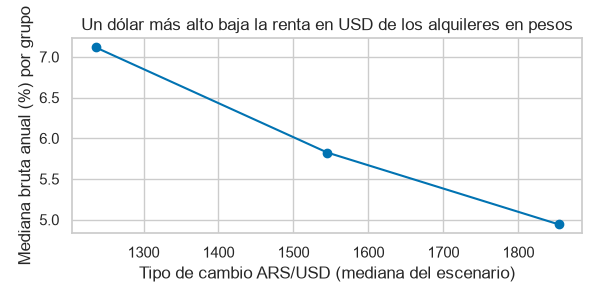

In [16]:
costos=comparables_amplios.loc[comparables_amplios.n_expensas_venta.ge(5)].copy()
for meses in [0,1,2]:
    costos[f'Neta_condicional_vacancia_{meses}m_%']=100*((12-meses)*costos.precio_alquiler
        -12*costos.expensas_venta-.01*costos.precio_venta)/costos.precio_venta
colnet=[c for c in costos if c.startswith('Neta_')]
display(costos[['n_venta','n_alquiler','n_expensas_venta','Bruta_%']+colnet].sort_values('n_alquiler',ascending=False).head(12).round(2))
res_costos=pd.DataFrame({'Escenario':colnet,'n_grupos':len(costos),
    'Mediana_%':[costos[c].median() for c in colnet],
    'n_no_positivos':[(costos[c]<=0).sum() for c in colnet]})
display(res_costos.round(2))

cambio=[]
tc_scraping=alquiler_amplio['TC_Scraping']
escenarios=[('Scraping -20%',tc_scraping*.8),('Scraping',tc_scraping),('Scraping +20%',tc_scraping*1.2)]
for nombre,tc in escenarios:
    a=alquiler_amplio.copy()
    a['Precio_USD']=np.select([a.Moneda.eq('USD'),a.Moneda.eq('ARS')],[a.Precio,a.Precio/tc],default=np.nan)
    c=comparables(a)
    cambio.append((nombre,tc.median(),len(c),c['Bruta_%'].median()))
cambio=pd.DataFrame(cambio,columns=['Escenario','ARS_por_USD','n_grupos','Mediana_bruta_%_por_grupo'])
display(cambio.round(2))
fig,ax=plt.subplots(figsize=(6,3))
ax.plot(cambio.ARS_por_USD,cambio['Mediana_bruta_%_por_grupo'],marker='o')
ax.set(xlabel='Tipo de cambio ARS/USD (mediana del escenario)',ylabel='Mediana bruta anual (%) por grupo',
       title='Un dólar más alto baja la renta en USD de los alquileres en pesos')
plt.tight_layout(); plt.show()

El cálculo de costos usa los grupos con suficientes expensas. La vacancia reduce el flujo y la conversión a USD depende de la moneda de cada aviso. Los escenarios ilustran esa exposición con los supuestos de la tabla.

**Lectura del resultado ejecutado.** Entre los **125 grupos** con costo informado suficiente, la mediana neta condicional es **3,71%**, **3,19%** y **2,69%** con 0, 1 y 2 meses de vacancia respectivamente. No corresponde restar estos valores de la mediana bruta global como si compartieran idéntico universo. La mediana bruta del escenario cambiario varía de **7,12%** (1.236 ARS/USD, dólar del scraping −20%) a **5,83%** (1.545, dólar del scraping) y **4,94%** (1.854, +20%), sobre 133 grupos. Esto evidencia sensibilidad de moneda, no un rango probabilístico ni un pronóstico.

## 7. Evidencia y límites de las hipótesis
Los resultados bivariados y ajustados pueden discrepar por composición. “Compatible” describe dirección, no aceptación estadística definitiva ni causalidad. La formulación original completa de la propuesta debe incorporarse en una etapa posterior para contrastar exactamente sus predicciones.

In [17]:
evidencia=[]
for op,m in modelos.items():
    for h,t,direccion in [('H4 transporte','log_subte','distancia negativa compatible con prima por cercanía'),
                           ('H5 delitos','log_delitos','conteo negativo compatible con penalización'),
                           ('H7 verde × familiar','log_verde:familiar_num','interacción positiva compatible con mayor asociación familiar')]:
        lo,hi=m.conf_int().loc[t]
        evidencia.append((h,op,m.params[t],lo,hi,'Incluye cero' if lo<=0<=hi else 'No incluye cero',direccion))
evidencia=pd.DataFrame(evidencia,columns=['Hipotesis_referida_EDA','Operacion','beta_ajustado','IC95_inf','IC95_sup','IC_descriptivo_HC3','Direccion_de_referencia'])
display(evidencia.round(4))

,Hipotesis_referida_EDA,Operacion,beta_ajustado,IC95_inf,IC95_sup,IC_descriptivo_HC3,Direccion_de_referencia
0,H4 transporte,Venta,0.002,-0.002,0.007,Incluye cero,distancia negativa compatible con prima por cercanía
1,H5 delitos,Venta,-0.037,-0.047,-0.027,No incluye cero,conteo negativo compatible con penalización
2,H7 verde × familiar,Venta,0.008,0.004,0.012,No incluye cero,interacción positiva compatible con mayor asociación familiar
3,H4 transporte,Alquiler,0.017,-0.001,0.035,Incluye cero,distancia negativa compatible con prima por cercanía
4,H5 delitos,Alquiler,-0.102,-0.138,-0.067,No incluye cero,conteo negativo compatible con penalización
5,H7 verde × familiar,Alquiler,-0.002,-0.015,0.012,Incluye cero,interacción positiva compatible con mayor asociación familiar


Los contrastes ajustados por barrio y la corrección por comparaciones múltiples se desarrollan en el notebook 05. Esta tabla organiza la evidencia exploratoria.

**Balance de evidencia del corte analizado.**
- **H4:** la asociación bivariada distancia-precio/m² es débil y difiere por operación (venta −0,096; alquiler +0,045). Ajustando por atributos y barrio, los coeficientes de log-distancia son positivos muy pequeños y ambos IC95% HC3 incluyen cero. Este ajuste **no aporta evidencia clara de una prima por cercanía al subte**; no prueba ausencia de efecto real.
- **H5:** el conteo de delitos tiene coeficiente ajustado negativo en ambas operaciones, pero su magnitud cambia con extremos. Es asociación condicional compatible con una penalización de precios, **no efecto causal de inseguridad** ni una tasa de riesgo.
- **H7:** la interacción familiar-verde es positiva en venta base, pero cambia de signo en sensibilidad; en alquiler base el IC incluye cero. **No hay apoyo robusto a un premio diferencial familiar**, aunque el verde se asocie positivamente con precios en varias comparaciones.

Una prima en venta puede encarecer la compra tanto como una prima en alquiler aumenta ingreso. Ninguna de estas asociaciones, por sí sola, demuestra mayor rentabilidad Buy to Rent.

## 8. Conclusiones, limitaciones y próximos pasos
### Conclusiones reproducibles

Los extremos plausibles se conservan con banderas auditables. La modalidad desconocida y la diferencia de superficie entre ventas y alquileres limitan la comparabilidad. Los coeficientes describen asociaciones observadas.

### Limitaciones
- Muestra de publicaciones activas de una plataforma; no inventario completo, demanda, transacciones, ocupación ni días hasta alquilar. Duplicados entre avisos distintos pueden persistir.
- Precios solicitados, alquileres no emparejados y modalidad poco identificada. Los grupos con ≥5 tienen más incertidumbre que grupos grandes; no se produjeron intervalos de retorno ni ordenamiento definitivo de oportunidades.
- Faltantes y anomalías no aleatorios: casos completos, expensas positivas y cobertura geográfica pueden seleccionar segmentos. Los flags requieren auditoría de su definición y precisión.
- Amenities cero significan no informado/no detectado, no ausencia física. Antigüedad cero puede ser pozo o estreno. La proxy de unidad familiar no identifica habitantes.
- Ubicaciones aproximadas, validación rectangular y distancias en línea recta; conteos de delitos no normalizados por población, exposición o denuncia. Entorno medido antes del scraping; no riesgo actual ni probabilidad individual.
- OLS log-lineal puede omitir no linealidades, estado y calidad. Hay dependencia espacial, multicolinealidad y sesgo de selección; HC3 no los corrige. Ajuste in-sample, sin validación temporal/espacial ni interpretación causal.
- Renta bruta y neta condicional dependen de conversión, mantenimiento, comparables y quién paga expensas; no incorporan todos los costos o revalorización. Los KPIs existentes tienen filtros distintos y no son evidencia independiente.

### Próximos pasos priorizados
1. Auditar manualmente IDs marcados contra textos/origen; validar monedas, unidades, centinelas y ceros verdaderos de expensas. Solo entonces acordar correcciones persistentes con el grupo, sin sobrescribir fuentes.
2. Incorporar la redacción completa de las hipótesis; mejorar clasificación tradicional/temporario/desconocido y registrar cobertura por segmento.
3. Refinar comparables por superficie/estado, controlar duplicados de inmuebles y obtener intervalos mediante remuestreo de grupos o bloques espaciales.
4. Validar coordenadas con polígono oficial, tasas de delitos y accesibilidad caminable; evaluar no linealidad y validación por barrio/tiempo para precios, sin fuga desde KPIs derivados.
5. Construir flujos por propiedad con costos a cargo del dueño, vacancia, impuestos y compra/venta; inspeccionar oportunidades reales antes de recomendar inversiones.

## 9. Control final de integridad

In [18]:
assert len(df) == len(df_original) == N
pd.testing.assert_frame_equal(df_original, pd.read_csv(RUTA, low_memory=False))
assert {str(p): sha256(p) for p in PROTEGIDOS} == HASH_INICIAL
print('OK: fuente y archivos revisados sin modificaciones; filas conservadas; ningún export generado.')
print('Versiones:', {p: metadata.version(p) for p in ['pandas','numpy','matplotlib','seaborn','statsmodels']})
print('Python:', sys.version.split()[0])
for ruta,h in HASH_INICIAL.items(): print(ruta, h)

OK: fuente y archivos revisados sin modificaciones; filas conservadas; ningún export generado.
Versiones: {'pandas': '2.3.3', 'numpy': '2.5.3', 'matplotlib': '3.11.1', 'seaborn': '0.13.2', 'statsmodels': '0.15.0'}
Python: 3.13.12
data/processed/dataframe_limpio.csv 4d7b17003094c91492b2fa8941da5b0945065addc7142e5c3cee3c9bacb19d60
README.md 1a791da5b74a9e542b639422a6000f232a6f172cfbe7aaaa7a29cf83f69b3083
notebooks/03_eda_inicial.ipynb f19771db3bd3625a39223835852fd7e98b3a3457f0bec7a0575fcb7b901030cb
